# Sub-metric: Bus Access
**Author:** Owen (Group 23)

**Question:** Which Pittsburgh neighborhood has the best access to public transit?

**Dataset:** [Pittsburgh Regional Transit Stops (WPRDC)](https://data.wprdc.org/dataset/prt-of-allegheny-county-transit-stops) — every PRT stop with its location, neighborhood (`hood`), routes, and number of scheduled trips (`trips_wd`, `trips_sa`, `trips_su`, `trips_7d`).

**Idea:** A neighborhood has good bus access if it has (1) many stops, (2) frequent service at those stops, and (3) many different routes, so you can get to many places.

In [47]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [48]:
stops = pd.read_csv("data/prt_stops.csv")
print(stops.shape)
print(stops["trips_wd"].dtype)

(6389, 37)
int64


In [49]:
stops[["stop_name", "hood", "muni", "mode", "stop_route", "trips_wd"]].head(10)

,stop_name,hood,muni,mode,stop_route,trips_wd
0,DUQUESNE INCLINE AT LOWER STATION,South Shore,"Pittsburgh city (Allegheny, PA)",INCLINE,W06290,73
1,DUQUESNE INCLINE AT UPPER STATION,Mount Washington,"Pittsburgh city (Allegheny, PA)",INCLINE,W06300,73
2,MONONGAHELA INCLINE AT UPPER STATION,Mount Washington,"Pittsburgh city (Allegheny, PA)",INCLINE,W15307,78
3,MONONGAHELA INCLINE AT LOWER STATION,South Shore,"Pittsburgh city (Allegheny, PA)",INCLINE,W15308,78
4,26TH ST AT PENN AVE FS (SPRING WAY),Strip District,"Pittsburgh city (Allegheny, PA)",BUS,E00175,120
5,28TH ST AT LIBERTY AVE,Polish Hill,"Pittsburgh city (Allegheny, PA)",BUS,E00180,28
6,32ND ST AT SPRING WAY,Strip District,"Pittsburgh city (Allegheny, PA)",BUS,E00270,119
7,40TH ST AT BUTLER ST,Lower Lawrenceville,"Pittsburgh city (Allegheny, PA)",BUS,E00420,30
8,40TH ST AT DAVIDSON ST FS,Central Lawrenceville,"Pittsburgh city (Allegheny, PA)",BUS,E00430,30
9,40TH ST OPP DAVIDSON ST,Lower Lawrenceville,"Pittsburgh city (Allegheny, PA)",BUS,E00500,66


The dataset has **6389 stops** and **37 columns**. The columns most useful for my metric are `hood` (neighborhood), `muni` (municipality), `stop_route` (routes serving the stop), and `trips_wd` (weekday trips).

In [50]:
print(stops["mode"].value_counts())
print()
print(stops["muni"].value_counts().head(10))

mode
BUS        6285
RAIL        100
INCLINE       4
Name: count, dtype: int64

muni
Pittsburgh city (Allegheny, PA)             2669
Penn Hills township (Allegheny, PA)          264
West Mifflin borough (Allegheny, PA)         172
Wilkinsburg borough (Allegheny, PA)          160
Ross township (Allegheny, PA)                156
Monroeville municipality (Allegheny, PA)     124
McKeesport city (Allegheny, PA)              114
McCandless township (Allegheny, PA)          106
Mount Lebanon township (Allegheny, PA)       100
Scott township (Allegheny, PA)                99
Name: count, dtype: int64


In [51]:
stops[["stop_id", "stop_name", "stop_route", "route_code", "route_filter"]].head(10)

,stop_id,stop_name,stop_route,route_code,route_filter
0,W06290,DUQUESNE INCLINE AT LOWER STATION,W06290,DQI,All Routes
1,W06300,DUQUESNE INCLINE AT UPPER STATION,W06300,DQI,All Routes
2,W15307,MONONGAHELA INCLINE AT UPPER STATION,W15307,MI,All Routes
3,W15308,MONONGAHELA INCLINE AT LOWER STATION,W15308,MI,All Routes
4,E00175,26TH ST AT PENN AVE FS (SPRING WAY),E00175,"54,88,91",All Routes
5,E00180,28TH ST AT LIBERTY AVE,E00180,54,All Routes
6,E00270,32ND ST AT SPRING WAY,E00270,"54,88,91",All Routes
7,E00420,40TH ST AT BUTLER ST,E00420,93,All Routes
8,E00430,40TH ST AT DAVIDSON ST FS,E00430,93,All Routes
9,E00500,40TH ST OPP DAVIDSON ST,E00500,"64,93",All Routes


In [52]:
print("Duplicate stop_id:", stops["stop_id"].duplicated().sum())
print("Missing hood:", stops["hood"].isna().sum())
print("Stops with 0 weekday trips:", (stops["trips_wd"] == 0).sum())

Duplicate stop_id: 0
Missing hood: 3720
Stops with 0 weekday trips: 5


## What I found while exploring
- Most stops are bus stops (6,285), plus 100 light rail stops and 4 incline stations.
- 2,669 stops are inside the City of Pittsburgh.
- The `route_code` column lists all routes serving a stop, separated by commas (e.g. "54,88,91"). The `stop_route` column is just the stop ID, so I don't use it.
- 3,720 stops have no neighborhood (`hood`). This is exactly the number of stops outside the city (6,389 − 2,669), so every stop inside Pittsburgh has a neighborhood label.
- There are no duplicate stops, and only 5 stops have zero weekday trips.

## Cleaning the data
The dataset covers all of Allegheny County, but our project is only about Pittsburgh, so I keep only stops where `muni` is "Pittsburgh city". I also remove stops with no neighborhood label, stops with zero weekday trips (inactive), and duplicate stops.
I keep all three modes (bus, light rail, and incline), because they are all public transit that people use to get around. Light rail is especially important for neighborhoods in the South Hills.

In [53]:
pgh = stops[stops["muni"] == "Pittsburgh city (Allegheny, PA)"].copy()
print("Pittsburgh stops:", len(pgh))

pgh = pgh[pgh["hood"].notna()]
pgh = pgh[pgh["trips_wd"] > 0]
pgh = pgh.drop_duplicates(subset="stop_id")

print("Active Pittsburgh stops:", len(pgh))
print("Neighborhoods:", pgh["hood"].nunique())

Pittsburgh stops: 2669
Active Pittsburgh stops: 2666
Neighborhoods: 89


After cleaning, I have **2,666 active stops across 89 neighborhoods**.

## Measuring transit access by neighborhood
For each neighborhood I calculate three things:
1. **Number of stops**: how many places you can get on a bus or train.
2. **Weekday trips**: the total number of times a bus or train stops in the neighborhood on a weekday. This measures how frequent the service is.
3. **Number of routes**: how many different lines serve the neighborhood. More routes means you can reach more places without transferring.

In [54]:
hood_stats = pgh.groupby("hood").agg(
    num_stops=("stop_id", "count"),
    weekday_trips=("trips_wd", "sum"),
)
hood_stats.sort_values("num_stops", ascending=False).head(10)

,num_stops,weekday_trips
hood,,
Mount Washington,97,3428
Bloomfield,93,5984
Lincoln-Lemington-Belmar,80,4151
Squirrel Hill North,76,7821
Shadyside,76,7560
Brookline,71,2845
Greenfield,71,3960
Squirrel Hill South,70,5720
Hazelwood,69,2718


In [55]:
routes = pgh[["hood", "route_code"]].dropna().copy()
routes["route"] = routes["route_code"].astype(str).str.split(",")
routes.head()

,hood,route_code,route
0,South Shore,DQI,[DQI]
1,Mount Washington,DQI,[DQI]
2,Mount Washington,MI,[MI]
3,South Shore,MI,[MI]
4,Strip District,"54,88,91","[54, 88, 91]"


In [56]:
routes = routes.explode("route")
routes["route"] = routes["route"].str.strip()
routes.head(10)

,hood,route_code,route
0,South Shore,DQI,DQI
1,Mount Washington,DQI,DQI
2,Mount Washington,MI,MI
3,South Shore,MI,MI
4,Strip District,"54,88,91",54
4,Strip District,"54,88,91",88
4,Strip District,"54,88,91",91
5,Polish Hill,54,54
6,Strip District,"54,88,91",54
6,Strip District,"54,88,91",88


In [57]:
hood_stats["num_routes"] = routes.groupby("hood")["route"].nunique()
hood_stats["num_routes"] = hood_stats["num_routes"].fillna(0).astype(int)

hood_stats.sort_values("num_routes", ascending=False).head(10)

,num_stops,weekday_trips,num_routes
hood,,,
Central Business District,69,14593,79
South Shore,15,3041,31
Shadyside,76,7560,26
South Oakland,17,2531,21
North Oakland,41,8145,20
Bluff,23,4052,20
Central Oakland,9,3368,19
Polish Hill,27,1421,18
West Oakland,32,6411,18


In [58]:
hood_stats.describe()

,num_stops,weekday_trips,num_routes
count,89.000000,89.000000,89.000000
mean,29.955056,2043.629213,7.662921
std,21.668950,2297.497929,9.814118
min,2.000000,30.000000,1.000000
25%,15.000000,630.000000,2.000000
50%,25.000000,1232.000000,5.000000
75%,39.000000,2845.000000,10.000000
max,97.000000,14593.000000,79.000000


### Observations
- The neighborhood with the most stops is **Mount Washington (97)**, and the one with the most routes is the **Central Business District (79)**.
- Mount Washington has the most stops but only average service, because it is a large hillside neighborhood. This shows that more stops does not always mean better access.
- South Shore has only 15 stops but 31 routes, because Station Square is a major transfer point where many bus and light rail lines meet.
- The data is very uneven. Downtown has 14,593 weekday trips, while the median neighborhood has only 1,232. That's about 12 times more.
- Weekday trips count every time a bus stops, so one bus passing 10 stops in a neighborhood counts 10 times. This measures how much service a neighborhood gets, not the number of buses.
- Larger neighborhoods naturally have more stops, so raw counts favor big neighborhoods.

## Combining into one score
The three measures are on very different scales, and the data is very uneven (downtown has about 12 times more trips than the median neighborhood). If I used raw numbers or min-max scaling, downtown would squeeze every other neighborhood close to 0.

Instead I convert each measure to a **percentile rank** from 0 to 1, which only depends on a neighborhood's position in the ranking. Then I average the three percentiles with equal weight to get the final **bus access score**.

In [59]:
for col in ["num_stops", "weekday_trips", "num_routes"]:
    hood_stats[col + "_pct"] = hood_stats[col].rank(pct=True)

hood_stats.sort_values("weekday_trips", ascending=False).head()

,num_stops,weekday_trips,num_routes,num_stops_pct,weekday_trips_pct,num_routes_pct
hood,,,,,,
Central Business District,69,14593,79,0.904494,1.000000,1.000000
North Oakland,41,8145,20,0.780899,0.988764,0.949438
Squirrel Hill North,76,7821,12,0.960674,0.977528,0.842697
Shadyside,76,7560,26,0.960674,0.966292,0.977528
West Oakland,32,6411,18,0.657303,0.955056,0.910112


In [60]:
hood_stats["bus_access_score"] = hood_stats[
    ["num_stops_pct", "weekday_trips_pct", "num_routes_pct"]
].mean(axis=1)

ranked = hood_stats.sort_values(
    ["bus_access_score", "weekday_trips"], ascending=False
)
ranked.head(10)
ranked[["num_stops", "weekday_trips", "num_routes", "bus_access_score"]].round(3).head(10)

,num_stops,weekday_trips,num_routes,bus_access_score
hood,,,,
Central Business District,69,14593,79,0.968
Shadyside,76,7560,26,0.968
Squirrel Hill North,76,7821,12,0.927
Mount Washington,97,3428,18,0.918
North Oakland,41,8145,20,0.906
Bloomfield,93,5984,11,0.906
Squirrel Hill South,70,5720,11,0.880
East Liberty,63,6245,11,0.873
Lincoln-Lemington-Belmar,80,4151,8,0.860


In [61]:
ranked.loc[["Central Business District", "Shadyside"], "bus_access_score"]

hood
Central Business District    0.968165
Shadyside                    0.968165
Name: bus_access_score, dtype: float64

In [62]:
ranked[["num_stops", "weekday_trips", "num_routes", "bus_access_score"]].round(3).tail(10)

,num_stops,weekday_trips,num_routes,bus_access_score
hood,,,,
Fairywood,9,270,1,0.116
Arlington-Arlington Heights,8,304,1,0.110
Mt. Oliver,9,188,1,0.097
Swisshelm Park,3,33,2,0.088
Hays,7,189,1,0.082
Chartiers City,6,180,1,0.071
East Carnegie,4,112,1,0.062
New Homestead,4,108,1,0.058
St. Clair,2,44,1,0.043


### Result
The **Central Business District** and **Shadyside** have exactly the same bus access score (about 0.968). They get there in different ways. Downtown is first in weekday trips and routes, but only around the top 10% in number of stops, while Shadyside ranks in the top 4% on all three measures. I break the tie with weekday trips, so the **Central Business District** comes first, followed by **Shadyside** and **Squirrel Hill North**.

However, downtown is mostly offices, and the reason it has so much service is that almost every route goes there. For someone choosing a place to *live*, Shadyside may be the more meaningful winner.

The neighborhoods with the worst access are **Ridgemont** and **St. Clair**, which have only 2 stops and 1 route each. Most of the bottom 10 (such as New Homestead, East Carnegie, and Fairywood) are small residential neighborhoods on the edge of the city.

## Visualizing the results

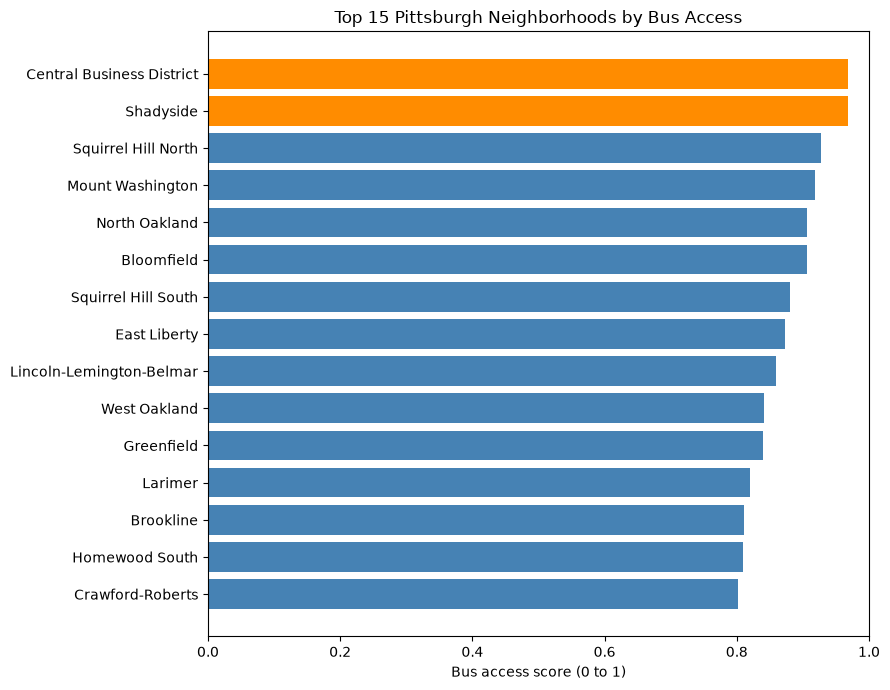

In [63]:
top15 = ranked.head(15).iloc[::-1]

colors = ["darkorange" if hood in ["Central Business District", "Shadyside"] else "steelblue"
          for hood in top15.index]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top15.index, top15["bus_access_score"], color=colors)
ax.set_title("Top 15 Pittsburgh Neighborhoods by Bus Access")
ax.set_xlabel("Bus access score (0 to 1)")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

The Central Business District and Shadyside (orange) are tied for first place. Most of the top 15 are in the East End and Oakland, the busiest transit corridor in the city.

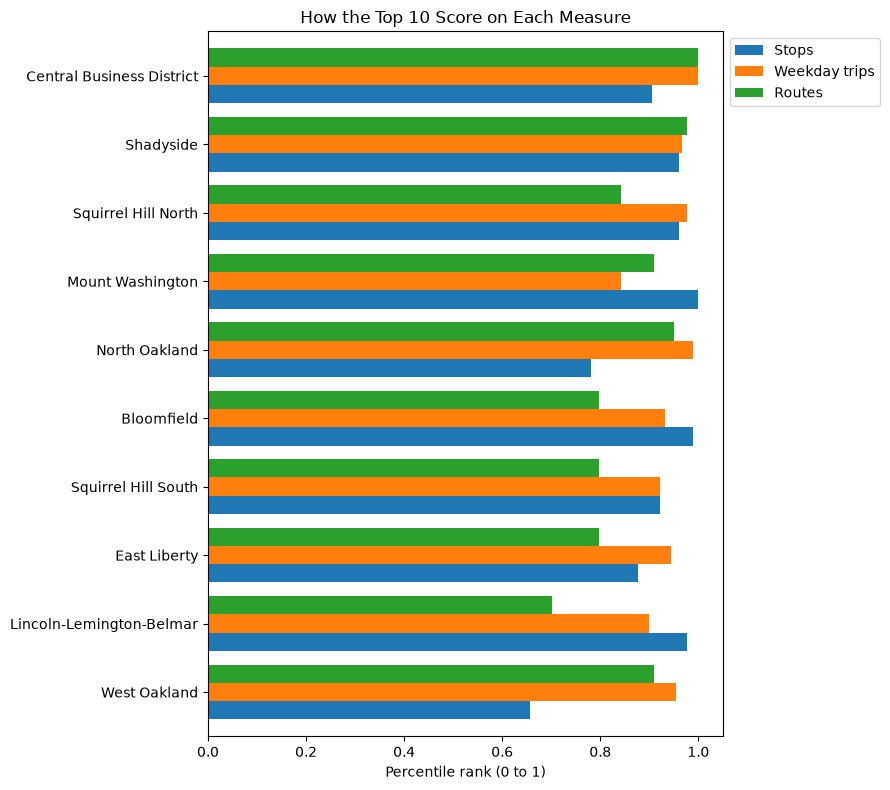

In [66]:
top10 = ranked.head(10).iloc[::-1]

ax = top10[["num_stops_pct", "weekday_trips_pct", "num_routes_pct"]].plot(
    kind="barh", figsize=(9, 8), width=0.8
)
ax.set_title("How the Top 10 Score on Each Measure")
ax.set_xlabel("Percentile rank (0 to 1)")
ax.set_ylabel("")
ax.legend(["Stops", "Weekday trips", "Routes"], loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

This chart shows why the two winners tie. Downtown is at the top for weekday trips and routes, but lower for number of stops. Shadyside is consistently high on all three. Mount Washington is the opposite of downtown: it has the most stops of any neighborhood, but fewer trips.